# Week 4, Tasks 4–5: evaluating the JCM control climatology

The control (Task 3, `results/w4-control_monthly.nc`) is SPEEDY at T31 with 8 sigma levels, run with
present-day climatological SST, sea ice and land forcing and CO2 = 420 ppmv, 2000–2010. Year 2000 is spin-up, so
everything here uses **2001–2010**.

It is compared with:

| | Source | Period | Variables |
|---|---|---|---|
| **ERA5** | Copernicus CDS monthly means | 2005–2014 | TOA: incoming SW, reflected SW, OLR |
| | WeatherBench2 6-hourly climatology (public Google Cloud copy) | 1990–2019 | tas, pr, T, u, v |
| **NorESM2-LM** | CMIP6 `historical`, monthly, mean of members r1–r3 (Pangeo) | 2005–2014 | tas, pr, all TOA terms, T, u, v |

Both were made by [`week4/get_obs.py`](../week4/get_obs.py), regridded bilinearly to the T31 grid, with the
same variable names and units as the control. Choices that differ from the brief:

- **ERA5 is not from NCAR's RDA:** we don't use Casper this week. The WeatherBench2 climatology
  covers 1990–2019 rather than the forcing years 2005–2014 (centres 5 years apart), and is smoothed over a few weeks
  in time, which slightly damps the DJF/JJA extremes.
- **ERA5 TOA fluxes come from Copernicus (CDS) instead:** WeatherBench2 lists them, but every value is NaN. CDS has the
  official ERA5 monthly means, so the TOA terms do match the forcing years 2005–2014.
- **NorESM2-LM from CMIP6, not ClimateBench:** the same model and the same three members as the Weeks 1–2 data, but
  ClimateBench only has annual anomalies of tas and pr, so seasons, T, u, v and the TOA terms need the monthly CMIP6 output.

Global means are cos(lat)-weighted. Seasonal and annual means weight months by their length. JCM levels are
selected by value, never by index.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

REPO = os.path.abspath("..")          # this notebook lives in <repo>/notebooks
assert os.path.exists(f"{REPO}/results/w4-control_monthly.nc"), "run from the notebooks/ folder"
FIGS = f"{REPO}/figures"
RESULTS = f"{REPO}/results"

P0 = 1.0e5        # Pa; JCM's ps_norm is ps / p0 (p0 in jcm/constants.py)
RADIUS = 6.371e6  # m
GRAV = 9.81       # m s-2
DAYS = xr.DataArray([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], dims="month",
                    coords={"month": np.arange(1, 13)})
SEASONS = {"ANN": list(range(1, 13)), "DJF": [12, 1, 2], "JJA": [6, 7, 8]}
warnings.filterwarnings("ignore", message="invalid value encountered in create_collection")  # cartopy/shapely

## 1. Load the three climatologies

JCM's monthly climatology is the mean of each calendar month over 2001–2010. Precipitation goes to mm/day.

In [2]:
control = xr.open_dataset(f"{RESULTS}/w4-control_monthly.nc")
ctl = control.sel(time=slice("2001", "2010"))
assert ctl.sizes["time"] == 120
jcm = ctl.groupby("time.month").mean()
era5 = xr.open_dataset(f"{RESULTS}/w4-era5_clim.nc")
nor = xr.open_dataset(f"{RESULTS}/w4-noresm2_clim.nc")

for ds in (jcm, era5, nor):
    np.testing.assert_allclose(ds.lat, control.lat)
    np.testing.assert_allclose(ds.lon, control.lon)
    for v in ["pr", "pr_gm"]:
        if v in ds:
            ds[v] = ds[v] * 86400
            ds[v].attrs["units"] = "mm/day"

print("JCM sigma levels (surface first):", jcm.level.values)
print("ERA5 pressure levels:", era5.plev.values)

JCM sigma levels (surface first): [0.9375 0.8125 0.6875 0.5625 0.4375 0.3125 0.1875 0.0625]
ERA5 pressure levels: [  50  100  150  200  250  300  400  500  600  700  850  925 1000]


In [3]:
def season_mean(da, season):
    months = SEASONS[season]
    return da.sel(month=months).weighted(DAYS.sel(month=months)).mean("month")


def gmean(da):
    return da.weighted(np.cos(np.deg2rad(da.lat))).mean(("lat", "lon"))


def _weights(a):
    return (np.cos(np.deg2rad(a.lat)) * xr.ones_like(a)).values.ravel()


def pattern_corr(a, b):
    # cos(lat)-weighted, centred pattern correlation of two (lat, lon) maps
    w = _weights(a)
    x, y = a.values.ravel(), b.values.ravel()
    x = x - np.average(x, weights=w)
    y = y - np.average(y, weights=w)
    return np.average(x * y, weights=w) / np.sqrt(np.average(x * x, weights=w) * np.average(y * y, weights=w))


def rmse(a, b):
    return float(np.sqrt(np.average(((a - b) ** 2).values.ravel(), weights=_weights(a))))

## 2. Global means

JCM is averaged on its own grid. ERA5 and NorESM2 use the global means saved from their native grids.

In [4]:
rows = []
for var, unit in [("tas", "K"), ("pr", "mm/day")]:
    for s in SEASONS:
        rows.append({"variable": f"{var} ({unit})", "season": s,
                     "JCM": float(season_mean(gmean(jcm[var]), s)),
                     "ERA5": float(season_mean(era5[f"{var}_gm"], s)),
                     "NorESM2": float(season_mean(nor[f"{var}_gm"], s))})
global_means = pd.DataFrame(rows).set_index(["variable", "season"])
global_means["JCM - ERA5"] = global_means.JCM - global_means.ERA5
global_means.round(2)

JCM    ERA5  NorESM2  JCM - ERA5
variable    season                                     
tas (K)     ANN     287.96  287.52   288.20        0.44
            DJF     286.57  285.78   286.60        0.79
            JJA     289.49  289.21   289.73        0.28
pr (mm/day) ANN       2.92    2.93     2.85       -0.00
            DJF       2.89    2.91     2.85       -0.01
            JJA       2.98    2.99     2.93       -0.02

## 3. Near-surface temperature and precipitation maps

Each row is a season. The columns are JCM, ERA5, JCM − ERA5 and JCM − NorESM2. Panel titles give the area-weighted
pattern correlation *r* with the reference and the global-mean bias.

ERA5's 2 m temperature and JCM's near-surface temperature (`surface_flux.t0`) are defined slightly differently,
and the T31 orography is smoother than ERA5's. Some of the bias over mountains comes from those differences,
not from the model physics.

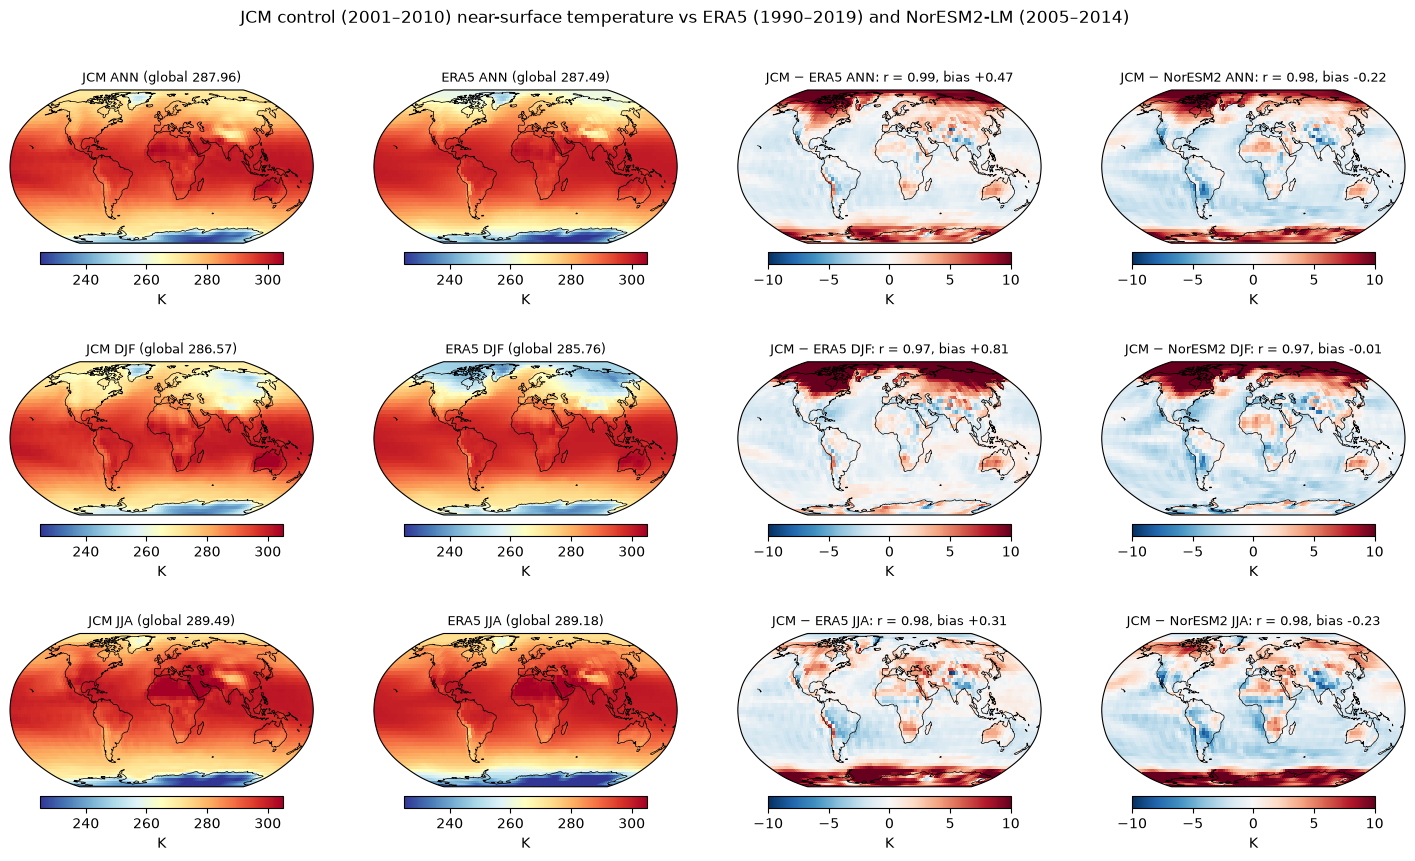

In [5]:
STYLE = {
    "tas": dict(name="near-surface temperature", unit="K", cmap="RdYlBu_r", vmin=225, vmax=305,
                dcmap="RdBu_r", dlim=10),
    "pr": dict(name="precipitation", unit="mm/day", cmap="YlGnBu", vmin=0, vmax=12,
               dcmap="BrBG", dlim=6),
}


def map_panel(ax, da, cmap, vmin, vmax, title, label):
    im = da.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, vmin=vmin, vmax=vmax,
                 add_colorbar=False, add_labels=False)
    ax.coastlines(linewidth=0.5)
    ax.set_title(title, fontsize=9)
    plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.8, pad=0.04, label=label)


def plot_maps(var):
    st = STYLE[var]
    fig, axes = plt.subplots(3, 4, figsize=(18, 10), subplot_kw={"projection": ccrs.Robinson()})
    for row, s in zip(axes, SEASONS):
        j, e, n = (season_mean(ds[var], s) for ds in (jcm, era5, nor))
        map_panel(row[0], j, st["cmap"], st["vmin"], st["vmax"],
                  f"JCM {s} (global {float(gmean(j)):.2f})", st["unit"])
        map_panel(row[1], e, st["cmap"], st["vmin"], st["vmax"],
                  f"ERA5 {s} (global {float(gmean(e)):.2f})", st["unit"])
        map_panel(row[2], j - e, st["dcmap"], -st["dlim"], st["dlim"],
                  f"JCM − ERA5 {s}: r = {pattern_corr(j, e):.2f}, bias {float(gmean(j - e)):+.2f}", st["unit"])
        map_panel(row[3], j - n, st["dcmap"], -st["dlim"], st["dlim"],
                  f"JCM − NorESM2 {s}: r = {pattern_corr(j, n):.2f}, bias {float(gmean(j - n)):+.2f}", st["unit"])
    fig.suptitle(f"JCM control (2001–2010) {st['name']} vs ERA5 (1990–2019) and NorESM2-LM (2005–2014)", y=0.93)
    fig.savefig(f"{FIGS}/week4_{var}_maps.png", dpi=150, bbox_inches="tight")


plot_maps("tas")

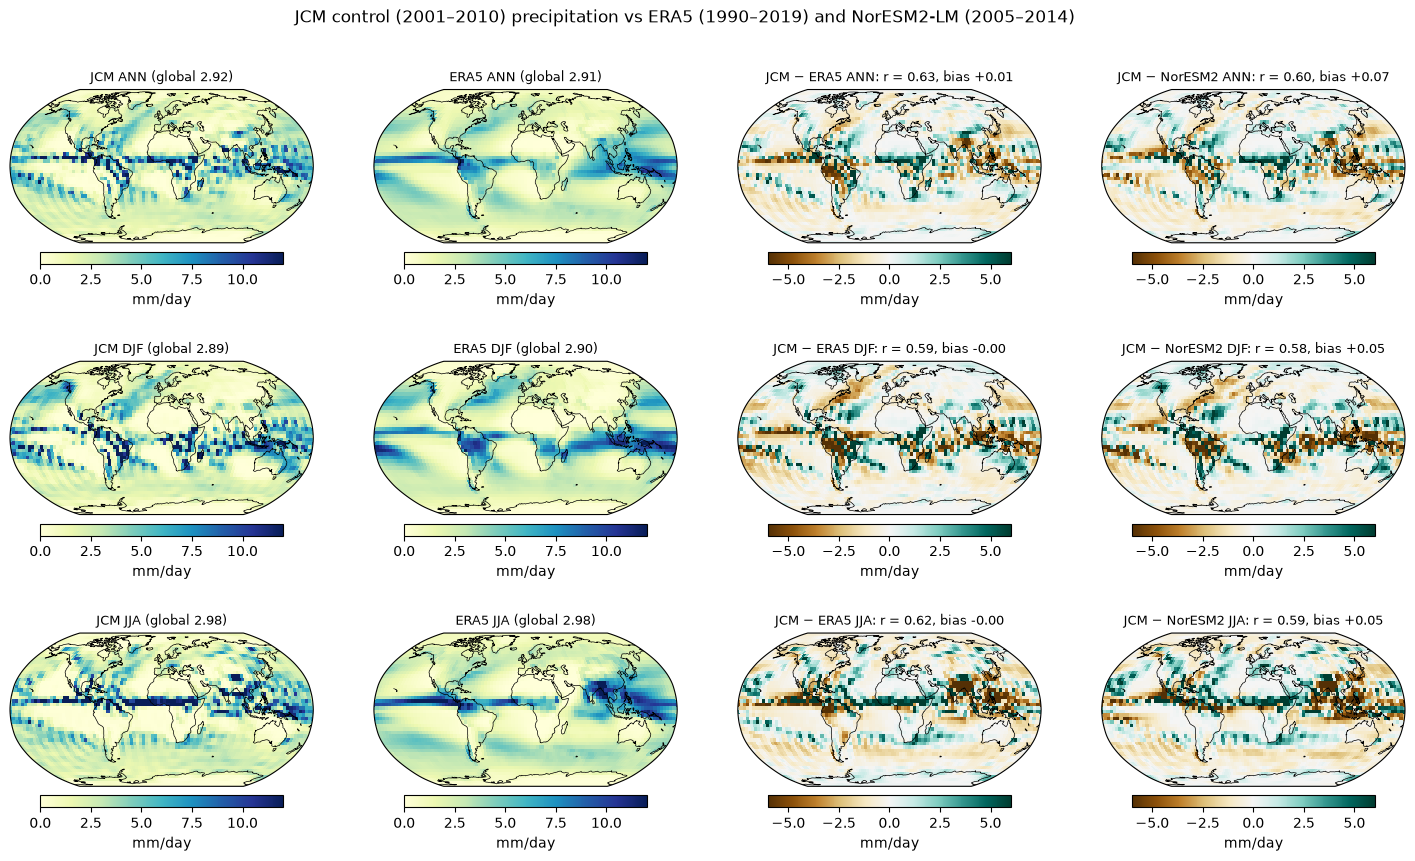

In [6]:
plot_maps("pr")

**Pattern correlations and RMSE.** The NorESM2 − ERA5 column is the benchmark: it shows how close a full CMIP6
model gets on the same grid.

In [7]:
rows = []
for var in ["tas", "pr"]:
    for s in SEASONS:
        j, e, n = (season_mean(ds[var], s) for ds in (jcm, era5, nor))
        rows.append({"variable": var, "season": s,
                     "r JCM-ERA5": pattern_corr(j, e), "r JCM-NorESM2": pattern_corr(j, n),
                     "r NorESM2-ERA5": pattern_corr(n, e),
                     "RMSE JCM-ERA5": rmse(j, e), "RMSE NorESM2-ERA5": rmse(n, e)})
scores = pd.DataFrame(rows).set_index(["variable", "season"])
scores.round(2)

r JCM-ERA5  r JCM-NorESM2  r NorESM2-ERA5  RMSE JCM-ERA5  \
variable season                                                             
tas      ANN           0.99           0.98            1.00           2.65   
         DJF           0.97           0.97            1.00           4.32   
         JJA           0.98           0.98            0.99           2.84   
pr       ANN           0.63           0.60            0.89           2.19   
         DJF           0.59           0.58            0.89           2.78   
         JJA           0.62           0.59            0.88           2.99   

                 RMSE NorESM2-ERA5  
variable season                     
tas      ANN                  1.53  
         DJF                  1.76  
         JJA                  1.90  
pr       ANN                  0.98  
         DJF                  1.24  
         JJA                  1.28

## 4. Zonal-mean temperature and zonal wind

JCM is on sigma levels. Its pressure is σ · p_s, using the zonal-mean surface pressure of each month and latitude.
It is interpolated (linear in log p) to the ERA5 pressure levels. Nothing is extrapolated, so levels above JCM's top
mid-level (σ = 0.0625, about 60 hPa) or below its lowest (σ = 0.9375) are blank. NorESM2 has all 13 ERA5 levels.

**Note on the vertical grid.** The control's levels are evenly spaced in sigma (0.0625 … 0.9375). This is not
SPEEDY's own 8-level table (boundaries 0, 0.05, 0.14, 0.26, 0.42, 0.6, 0.77, 0.9, 1). At the pinned jax-gcm
commit, the CLI's `grid: speedy_t31_l8` (`vertical: sigma`) builds `SigmaCoordinates.equidistant(8)`
(`jcm/runners.py`), while the Python helper `get_speedy_coords()` uses SPEEDY's table. So the control has a
thicker top layer and a coarser boundary layer than original SPEEDY.

In [8]:
assert np.allclose(np.diff(np.sort(jcm.level)), 0.125), "expected evenly spaced sigma"
ps_zm = jcm.ps_norm.mean("lon") * P0 / 100                  # (month, lat), hPa
PLEV = era5.plev.values.astype(float)


def sigma_to_pressure(field):
    # (month, level, lat) on sigma -> (month, plev, lat) on PLEV, linear in log p, no extrapolation
    p = field.level * ps_zm

    def column(f, pc):
        order = np.argsort(pc)
        return np.interp(np.log(PLEV), np.log(pc[order]), f[order], left=np.nan, right=np.nan)

    out = xr.apply_ufunc(column, field, p, input_core_dims=[["level"], ["level"]],
                         output_core_dims=[["plev"]], vectorize=True)
    return out.assign_coords(plev=PLEV).transpose("month", "plev", "lat")


jcm_p = xr.Dataset({v: sigma_to_pressure(jcm[v]) for v in ["ta", "ua", "va"]})
era5_p = era5[["ta", "ua", "va"]].astype(float)
nor_p = nor[["ta", "ua", "va"]].sel(plev=PLEV).astype(float)

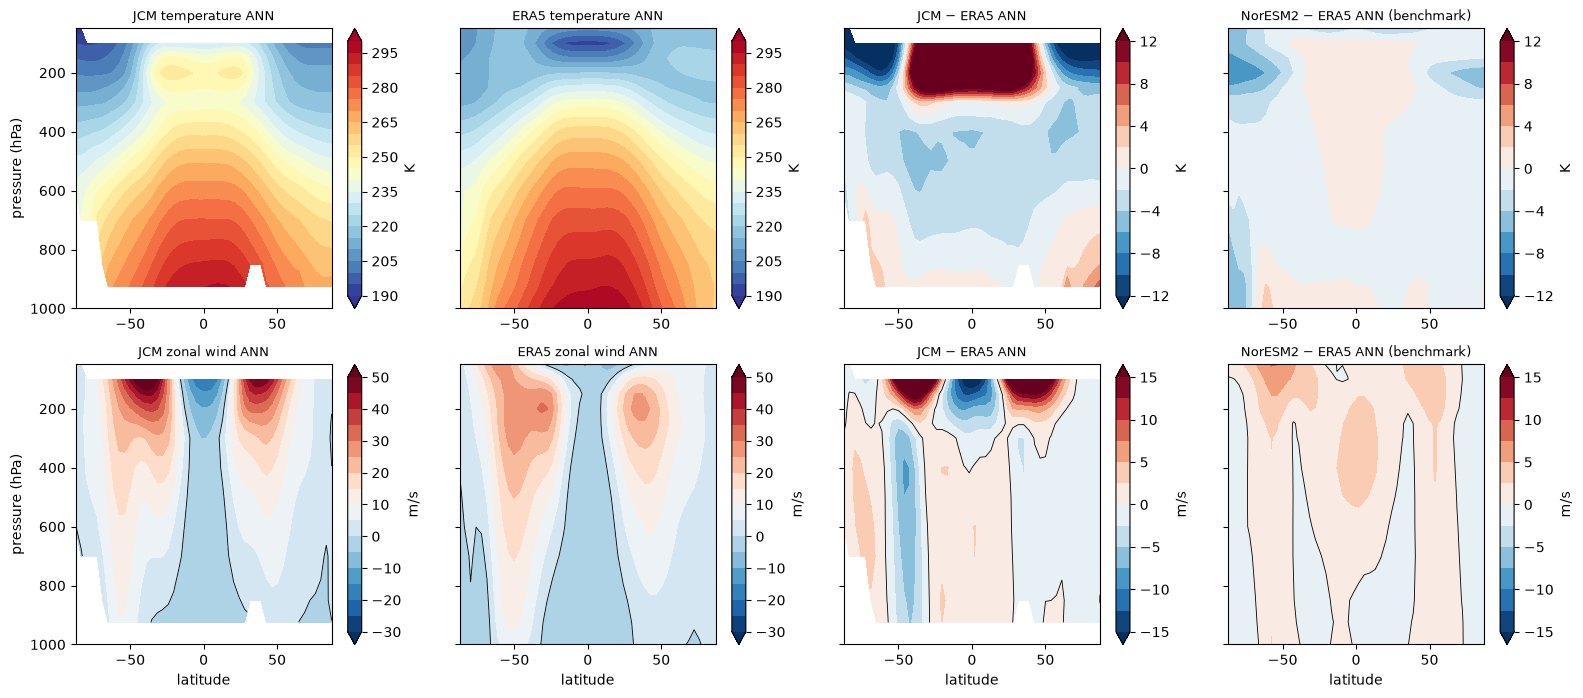

In [9]:
XSEC = {"ta": dict(name="temperature", unit="K", levels=np.arange(190, 305, 5), dlim=12, cmap="RdYlBu_r"),
        "ua": dict(name="zonal wind", unit="m/s", levels=np.arange(-30, 55, 5), dlim=15, cmap="RdBu_r")}


def xsec_panel(ax, da, levels, cmap, title, label):
    cf = ax.contourf(da.lat, da.plev, da, levels=levels, cmap=cmap, extend="both")
    if label == "m/s":
        ax.contour(da.lat, da.plev, da, levels=[0], colors="k", linewidths=0.6)
    ax.set_ylim(1000, 50)
    ax.set_title(title, fontsize=9)
    plt.colorbar(cf, ax=ax, label=label)


def plot_xsec(season):
    fig, axes = plt.subplots(2, 4, figsize=(19, 8), sharey=True)
    for row, var in zip(axes, XSEC):
        st = XSEC[var]
        j, e, n = (season_mean(ds[var], season) for ds in (jcm_p, era5_p, nor_p))
        dlev = np.linspace(-st["dlim"], st["dlim"], 13)
        xsec_panel(row[0], j, st["levels"], st["cmap"], f"JCM {st['name']} {season}", st["unit"])
        xsec_panel(row[1], e, st["levels"], st["cmap"], f"ERA5 {st['name']} {season}", st["unit"])
        xsec_panel(row[2], j - e, dlev, "RdBu_r", f"JCM − ERA5 {season}", st["unit"])
        xsec_panel(row[3], n - e, dlev, "RdBu_r", f"NorESM2 − ERA5 {season} (benchmark)", st["unit"])
        row[0].set_ylabel("pressure (hPa)")
    for ax in axes[-1]:
        ax.set_xlabel("latitude")
    fig.savefig(f"{FIGS}/week4_zonal_{season}.png", dpi=150, bbox_inches="tight")


plot_xsec("ANN")

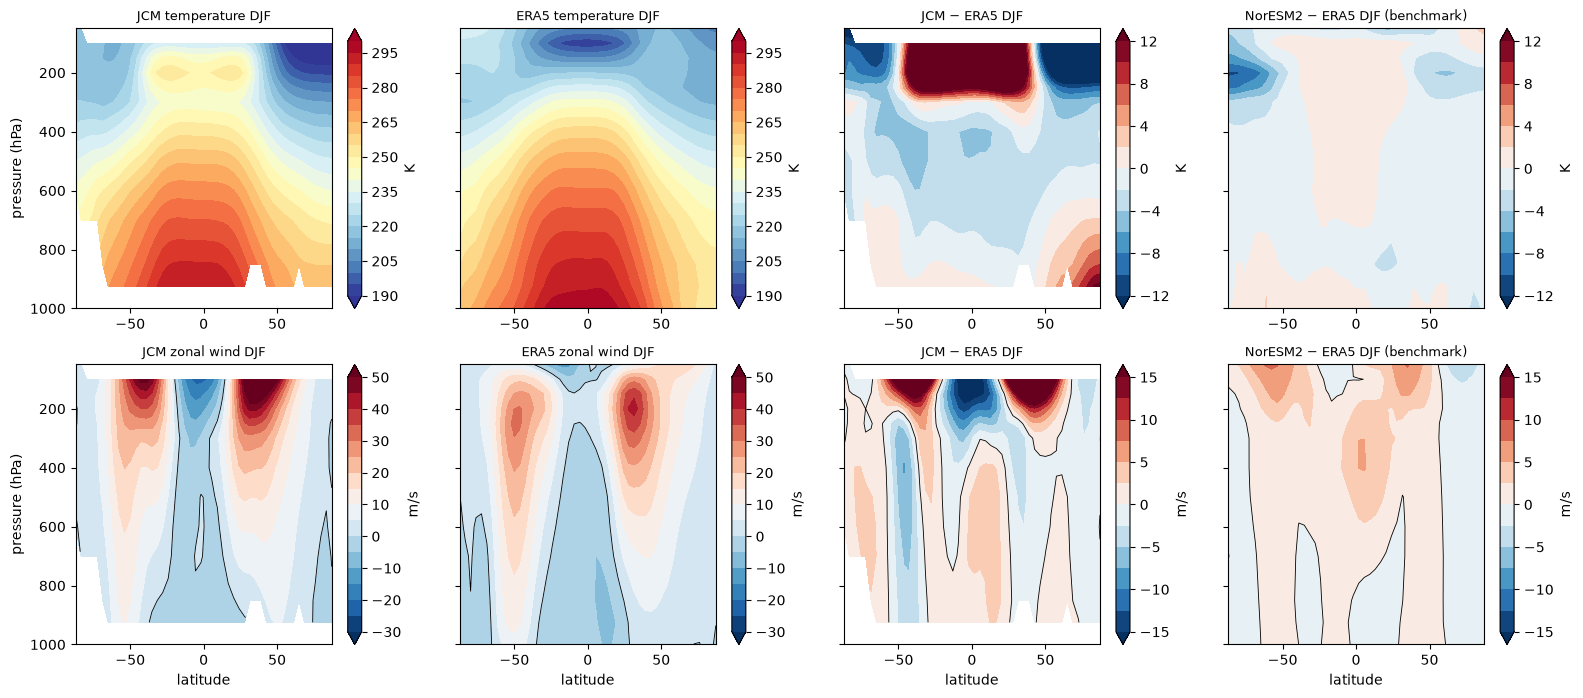

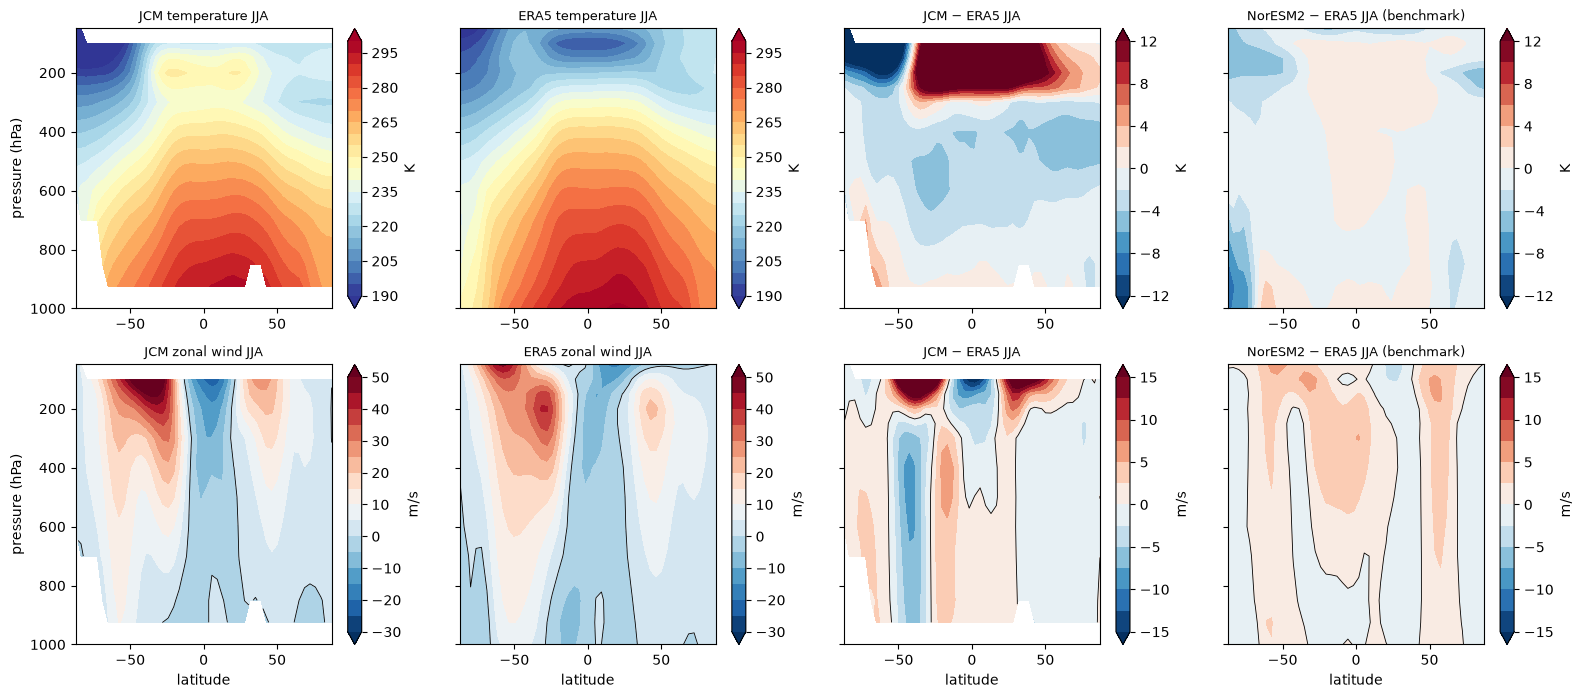

In [10]:
for s in ["DJF", "JJA"]:
    plot_xsec(s)

**The warm layer near 200 hPa is in the model output, not the interpolation.** JCM's own sigma levels over the
deep tropics (10°S–10°N, 2001–2010), next to ERA5 interpolated to the same pressure:

In [11]:
trop = slice(-10, 10)
t_jcm = season_mean(jcm.ta.sel(lat=trop).mean("lat"), "ANN")
t_era = season_mean(era5.ta.sel(lat=trop).mean("lat"), "ANN")
ps_trop = float(season_mean(ps_zm.sel(lat=trop).mean("lat"), "ANN"))
rows = []
for sig in t_jcm.level.values:                       # surface first
    p = sig * ps_trop
    rows.append({"sigma": sig, "p (hPa)": p, "JCM T (K)": float(t_jcm.sel(level=sig)),
                 "ERA5 T at p (K)": float(np.interp(np.log(p), np.log(t_era.plev), t_era))})
raw = pd.DataFrame(rows).set_index("sigma")
raw["JCM - ERA5"] = raw["JCM T (K)"] - raw["ERA5 T at p (K)"]
raw.round(1)

,p (hPa),JCM T (K),ERA5 T at p (K),JCM - ERA5
sigma,,,,
0.9375,950.5,296.3,295.8,0.5
0.8125,823.8,289.0,289.7,-0.7
0.6875,697.1,280.0,282.5,-2.5
0.5625,570.3,270.0,273.5,-3.5
0.4375,443.6,259.0,262.4,-3.4
0.3125,316.8,241.0,245.1,-4.1
0.1875,190.1,250.5,217.2,33.3
0.0625,63.4,215.4,201.7,13.6


The layer at σ = 0.1875 (about 190 hPa) is warmer than the layer below it: a temperature inversion where the real
tropical atmosphere is still cooling toward the tropopause (about 100 hPa). A likely cause is the vertical grid
above. JCM's SPEEDY treats every layer with σ < 0.2 as stratosphere (`STRATOSPHERE_SIGMA_THRESHOLD` in
`speedy_coords.py`: ozone shortwave heating, no water-vapour longwave absorption, the stratospheric cooling
correction). On SPEEDY's own table only the layers at σ ≈ 0.025 and 0.095 qualify, but on the evenly spaced grid the
layer at 0.1875 does too. This is a hypothesis: confirming it needs a control on SPEEDY's levels. The jets
below sit right on the poleward flanks of this warm layer.

**Jets.** Maximum zonal-mean u in each hemisphere, and where it sits.

In [12]:
rows = []
for name, ds in [("JCM", jcm_p), ("ERA5", era5_p), ("NorESM2", nor_p)]:
    for s in SEASONS:
        u = season_mean(ds.ua, s)
        for hemi, sl in [("SH", slice(-90, 0)), ("NH", slice(0, 90))]:
            uh = u.sel(lat=sl)
            i = np.unravel_index(int(np.nanargmax(uh.values)), uh.shape)
            rows.append({"data": name, "season": s, "hemisphere": hemi, "u max (m/s)": float(uh.values[i]),
                         "lat": float(uh.lat[i[1]]), "plev (hPa)": float(uh.plev[i[0]])})
jets = pd.DataFrame(rows).pivot_table(index=["season", "hemisphere"], columns="data",
                                      values=["u max (m/s)", "lat", "plev (hPa)"])
jets.round(1)

lat               plev (hPa)                u max (m/s)  \
data               ERA5   JCM NorESM2       ERA5    JCM NorESM2        ERA5   
season hemisphere                                                             
ANN    NH          35.3  39.0    35.3      200.0  100.0   200.0        27.1   
       SH         -31.5 -39.0   -57.5      200.0  100.0    50.0        31.0   
DJF    NH          31.5  35.3    31.5      200.0  100.0   200.0        41.8   
       SH         -50.1 -39.0   -50.1      250.0  100.0   200.0        31.4   
JJA    NH          42.7  39.0    46.4      200.0  100.0   200.0        21.7   
       SH         -57.5 -35.3   -57.5       50.0  100.0    50.0        46.4   

                                 
data                JCM NorESM2  
season hemisphere                
ANN    NH          50.4    27.3  
       SH          60.5    35.5  
DJF    NH          72.3    44.9  
       SH          52.4    33.7  
JJA    NH          28.3    22.1  
       SH          69.4    52.2

## 5. Hadley cell: mean meridional mass streamfunction

$$\psi(\varphi, p) = \frac{2\pi a\cos\varphi}{g}\int_0^p [v]\,dp'$$

For ERA5 and NorESM2, the integral runs down from 50 hPa on the 13 common levels. Below-ground NaNs in NorESM2
count as zero. For JCM, it is done on sigma, ψ = (2πa cos φ / g) · p_s · Σ [v] Δσ from the model top, which gives
ψ at the layer interfaces. Using the zonal-mean p_s instead of [p_s v] is an approximation. Positive ψ is clockwise
in these plots (northward flow aloft, southward near the surface), as in the NH winter cell during DJF.

max   min
season data               
DJF    JCM      11.2  -3.2
       ERA5     20.5  -4.3
       NorESM2  19.4  -3.5
JJA    JCM       1.2 -19.7
       ERA5      2.5 -24.0
       NorESM2   2.3 -21.6

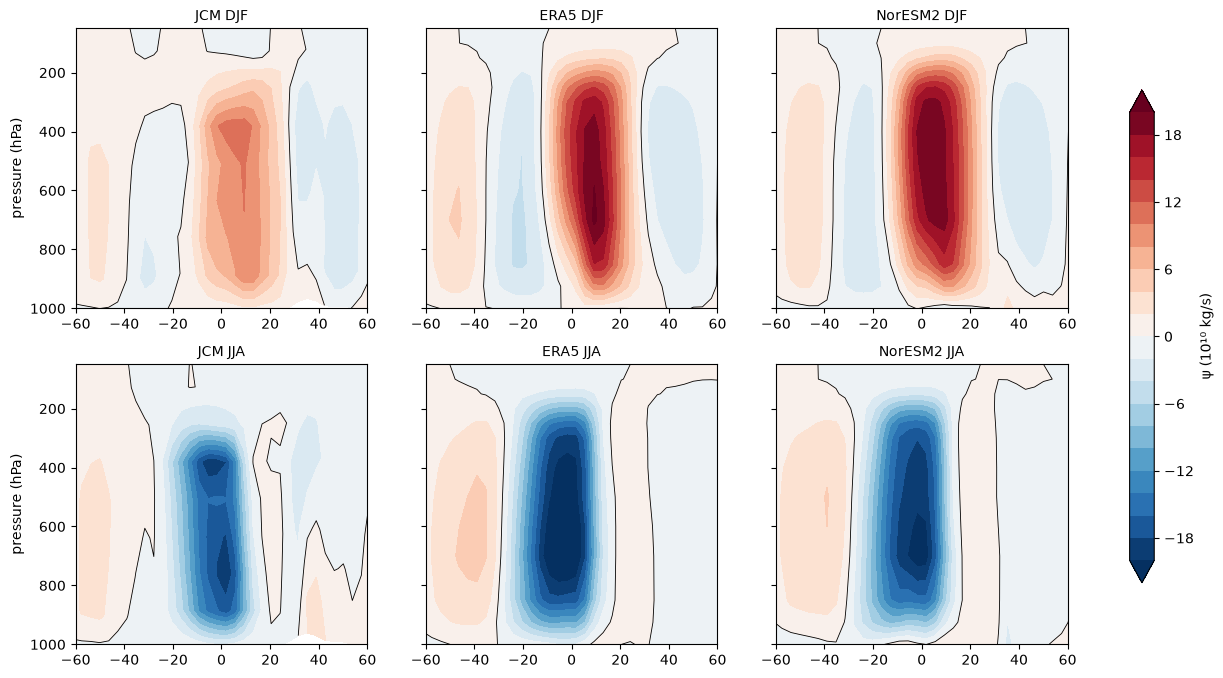

In [13]:
def psi_pressure(v):
    v = v.sortby("plev").fillna(0.0)
    integral = v.cumulative_integrate(coord="plev") * 100        # hPa -> Pa
    psi = 2 * np.pi * RADIUS * np.cos(np.deg2rad(v.lat)) / GRAV * integral / 1e10
    return psi.transpose("plev", "lat")


def psi_sigma(v, ps_hpa):
    # v: (level, lat) on evenly spaced sigma; returns psi on interfaces (sigma_half, lat) and their pressure
    v = v.sortby("level")                                       # top first
    dsig = 0.125
    psi = (v * dsig).cumsum("level")                            # at the bottom interface of each layer
    psi = 2 * np.pi * RADIUS * np.cos(np.deg2rad(v.lat)) / GRAV * ps_hpa * 100 * psi / 1e10
    sig_half = v.level.values + dsig / 2
    psi = psi.assign_coords(level=sig_half)
    top = xr.zeros_like(psi.isel(level=0)).assign_coords(level=0.0)
    psi = xr.concat([top, psi], "level").transpose("level", "lat")
    return psi, (psi.level * ps_hpa).transpose("level", "lat")


PSI_LEVELS = np.arange(-20, 22, 2)
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
hadley = []
for row, s in zip(axes, ["DJF", "JJA"]):
    psi_j, p_j = psi_sigma(season_mean(jcm.va, s), season_mean(ps_zm, s))
    lat2d = xr.broadcast(psi_j.lat, psi_j)[0].transpose("level", "lat")
    panels = [("JCM", lat2d, p_j, psi_j)]
    for name, ds in [("ERA5", era5_p), ("NorESM2", nor_p)]:
        psi = psi_pressure(season_mean(ds.va, s))
        panels.append((name, psi.lat, psi.plev, psi))
    for ax, (name, x, y, psi) in zip(row, panels):
        cf = ax.contourf(x, y, psi, levels=PSI_LEVELS, cmap="RdBu_r", extend="both")
        ax.contour(x, y, psi, levels=[0], colors="k", linewidths=0.6)
        ax.set_ylim(1000, 50)
        ax.set_xlim(-60, 60)
        ax.set_title(f"{name} {s}", fontsize=10)
        tropics = psi.where(np.abs(psi.lat) <= 35)
        hadley.append({"data": name, "season": s, "max": float(tropics.max()), "min": float(tropics.min())})
    row[0].set_ylabel("pressure (hPa)")
plt.colorbar(cf, ax=axes, label="ψ (10¹⁰ kg/s)", shrink=0.8)
fig.savefig(f"{FIGS}/week4_hadley.png", dpi=150, bbox_inches="tight")
pd.DataFrame(hadley).set_index(["season", "data"]).round(1)

## 6. Global-mean TOA energy budget

Annual means. Net is downward (absorbed SW − OLR). ERA5 is the CDS monthly means for 2005–2014.

JCM's incoming SW is higher because SPEEDY's shortwave uses an area-mean insolation `solc = 342.0` W m⁻²
(`jcm/physics/speedy/physical_constants.py`, i.e. S₀ ≈ 1368 W m⁻²), while CMIP6 uses S₀ = 1361 W m⁻² (≈ 340.25).

In [14]:
TOA = {"rsdt": "incoming SW", "rsut": "reflected SW", "rlut": "OLR", "rtnt": "net (down)"}
budget = pd.DataFrame({
    "JCM (2001–2010)": {TOA[v]: float(season_mean(gmean(jcm[v]), "ANN")) for v in TOA},
    "NorESM2-LM (2005–2014)": {TOA[v]: float(season_mean(nor[f"{v}_gm"], "ANN")) for v in TOA},
    "ERA5 (2005–2014)": {TOA[v]: float(season_mean(era5[f"{v}_gm"], "ANN")) for v in TOA},
})
budget.loc["planetary albedo"] = budget.loc["reflected SW"] / budget.loc["incoming SW"]
budget["JCM - ERA5"] = budget.iloc[:, 0] - budget.iloc[:, 2]
budget["JCM - NorESM2"] = budget.iloc[:, 0] - budget.iloc[:, 1]
budget.round(3)

,JCM (2001–2010),NorESM2-LM (2005–2014),ERA5 (2005–2014),JCM - ERA5,JCM - NorESM2
incoming SW,342.009,340.250,340.388,1.622,1.760
reflected SW,100.431,102.414,97.657,2.774,-1.983
OLR,236.662,237.272,242.022,-5.361,-0.611
net (down),4.917,0.563,0.708,4.209,4.354
planetary albedo,0.294,0.301,0.287,0.007,-0.007


## 7. Task 5: interannual variability of the TOA net flux

Annual global-mean net TOA flux, one value per year. The year-to-year standard deviation σ sets how long a run has
to be for its mean to have a standard error below 0.1 W m⁻²: N ≥ (σ / 0.1)², if the years are independent (checked
with the lag-1 autocorrelation). An ERF is the difference of two such runs, so its standard error is √2 times larger.
For SE(ERF) < 0.1 W m⁻², each run needs N ≥ 2 (σ / 0.1)².

annual global-mean net TOA, 2001-2010: mean 4.92 W/m2, sd 0.145 W/m2, lag-1 r -0.05
SE of the 10-year control mean: 0.046 W/m2
years for SE < 0.1 W/m2: 3 for one run's mean; 5 per run for an ERF (difference)
without 2001: sd 0.093 W/m2


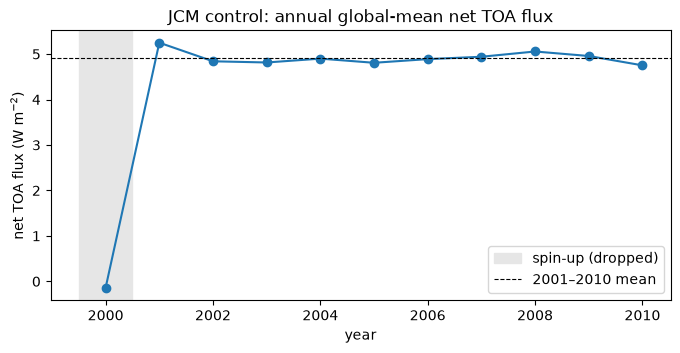

In [15]:
gm_month = gmean(control.rtnt)
dim = control.time.dt.days_in_month
annual = (gm_month * dim).groupby("time.year").sum() / dim.groupby("time.year").sum()
a = annual.sel(year=slice(2001, 2010))
sigma = float(a.std(ddof=1))
x = a.values - a.values.mean()
lag1 = float((x[1:] * x[:-1]).sum() / (x * x).sum())
n_single = int(np.ceil((sigma / 0.1) ** 2))
n_erf = int(np.ceil(2 * (sigma / 0.1) ** 2))

print(f"annual global-mean net TOA, 2001-2010: mean {float(a.mean()):.2f} W/m2, sd {sigma:.3f} W/m2, "
      f"lag-1 r {lag1:+.2f}")
print(f"SE of the 10-year control mean: {sigma / np.sqrt(10):.3f} W/m2")
print(f"years for SE < 0.1 W/m2: {n_single} for one run's mean; {n_erf} per run for an ERF (difference)")
print(f"without 2001: sd {float(a.sel(year=slice(2002, 2010)).std(ddof=1)):.3f} W/m2")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(annual.year, annual, "o-")
ax.axvspan(1999.5, 2000.5, color="0.9", label="spin-up (dropped)")
ax.axhline(float(a.mean()), color="k", lw=0.8, ls="--", label="2001–2010 mean")
ax.set_xlabel("year")
ax.set_ylabel("net TOA flux (W m$^{-2}$)")
ax.set_title("JCM control: annual global-mean net TOA flux")
ax.legend()
fig.savefig(f"{FIGS}/week4_toa_variability.png", dpi=150, bbox_inches="tight")

## 8. Summary

**Task 4: the climatology**

- **Global means are close.** Near-surface temperature is 287.96 K (ERA5 287.52, NorESM2 288.20) and
  precipitation 2.92 mm/day (ERA5 2.93, NorESM2 2.85). With SST prescribed, the ocean surface is pinned to
  observations, so global tas is close almost by construction.
- **Temperature patterns are right; the details are worse than a GCM's.** Pattern correlation with ERA5 is
  0.97–0.99, but RMSE is 2.7 K (ANN) to 4.3 K (DJF), against 1.5–1.9 K for NorESM2.
- **Precipitation patterns are much weaker.** r ≈ 0.6 with ERA5 against 0.89 for NorESM2. JCM's tropical rain is
  grid-scale and noisy, and the ITCZ structure is off, even though the global mean is right.
- **Upper troposphere.** The tropics are 30+ K too warm at about 190 hPa, with an inversion (see section 4). The jets
  are stronger than ERA5's in every season and hemisphere (annual mean 50 and 60 m/s in the NH and SH, against 27 and
  31) and peak near 100 hPa instead of 200. (ERA5's strongest JJA SH wind is the polar-night jet at 50 hPa, above
  JCM's top level.) The Hadley cell has the right
  shape and seasonal shift but is about 45% weaker in DJF (11 against 20 × 10¹⁰ kg/s) and about 20% weaker in JJA.
- **TOA budget.** Net +4.9 W m⁻², against +0.71 for ERA5 and +0.56 for NorESM2. Against ERA5, the +4.2 W m⁻²
  excess is +1.6 from SPEEDY's higher insolation (342.0 against 340.4 W m⁻²) and +5.4 from too little OLR (236.7
  against 242.0), partly offset by more reflected SW (100.4 against 97.7, albedo 0.294 against 0.287). The two
  references disagree by about 5 W m⁻² on reflected SW and on OLR, even though their nets agree, so the component
  biases are uncertain by a few W m⁻². The low OLR is the clearest signal. With fixed SSTs a non-zero imbalance is
  allowed (the prescribed ocean absorbs it). It measures how far the prescribed SSTs are from the model's own
  equilibrium.

**Task 5: variability and run length**

- The interannual SD of annual global-mean net TOA flux is 0.145 W m⁻² (2001–2010), with lag-1 autocorrelation −0.05,
  so the years are effectively independent. It is small because SSTs are fixed.
- SE < 0.1 W m⁻² needs 3 years for one run's mean, and **5 years per run** for an ERF (difference of two runs).
  The 10-year control alone has SE 0.046 W m⁻².
- 2001 (5.25 W m⁻²) is the largest value. Without it the SD is 0.093 W m⁻². The land may still be adjusting in
  year 2, so a 1-year spin-up plus 5 analysed years per perturbed run is a safe choice.

**Open questions**

- Does a control on SPEEDY's own sigma levels (`get_speedy_coords()`) remove the 190 hPa warm layer and the jet
  bias? This matters for Task 6 too: SPEEDY's CO2 absorption acts through the same layers.
- Why is JCM's OLR about 5 W m⁻² low? JCM's forcing config warns that its analytic ozone profile biases clear-sky OLR
  about 12 W m⁻² low (`jcm/config/forcing/default.yaml`), and the control uses that profile. Whether that applies
  to SPEEDY's radiation has not been checked.
- CERES-EBAF satellite fluxes would separate the ERA5/NorESM2 disagreement on the TOA components.